# Opening angle θ in Barnes-Hut: a closer look

`solver_comparison.ipynb` treated θ as a fixed knob (mostly θ = 0.5). This notebook makes θ the independent variable and asks:

1. **How does force error scale with θ**, and where does it stop following a power law?
2. **Who pays the error?** Which particles (radius, direction) and is the error biased or random?
3. **What does θ cost?** Time vs θ, speedup over direct summation, how the N-scaling and the direct/tree crossover move with θ.
4. **Is the error stable** across N and across random realisations?
5. **What does θ do to the dynamics?** Energy, momentum, virial ratio and half-mass radius under leapfrog.
6. **Which θ should I use** for a given error target?

Everything is computed here by calling the solvers through `compare.py` (same initial conditions, same softening, same reference), so the numbers are directly comparable to the main notebook.

In [8]:
# %pip install numba
import sys, time, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- configuration -------------------------------------------------------
PACKAGE      = "Henry"   # dotted name of the package containing direct.py, barnes_hut.py, ...
PROJECT_ROOT = ".."                  # folder that contains that package (added to sys.path)
BENCH_DIR    = "."                   # folder that contains compare.py
OUT          = Path("results_theta") # CSVs from this notebook are saved here
QUICK        = True                  # True = small, fast settings; False = full study (can take a long time)
EPS, G, SEED = 0.05, 1.0, 42
# --------------------------------------------------------------------------

for p in (PROJECT_ROOT, BENCH_DIR):
    if str(Path(p).resolve()) not in sys.path:
        sys.path.insert(0, str(Path(p).resolve()))
import compare

if QUICK:
    THETAS      = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 1.4]
    N_FORCE     = 1000                       # snapshot size for the detailed error analysis
    N_SWEEP     = (500, 1000, 2000, 4000)    # sizes for cost / N-dependence
    SEEDS       = range(3)
    N_CONS, STEPS, DIAG_EVERY, DT = 200, 100, 10, 0.01
    THETAS_CONS = (0.3, 0.5, 1.0)
else:
    THETAS      = [round(t, 2) for t in np.arange(0.1, 1.55, 0.1)]
    N_FORCE     = 4000
    N_SWEEP     = (1000, 2000, 4000, 8000, 16000, 32000)
    SEEDS       = range(10)
    N_CONS, STEPS, DIAG_EVERY, DT = 500, 300, 10, 0.01
    THETAS_CONS = (0.2, 0.3, 0.5, 0.7, 1.0)

modules = compare.load_solvers(PACKAGE)
REF  = compare.pick_reference(modules)                                 # exact solver used as ground truth
TREE = "fast_barnes_hut" if "fast_barnes_hut" in modules else "barnes_hut"   # tree solver swept over theta
if TREE not in modules:
    raise ImportError("No Barnes-Hut solver could be imported")
N_SWEEP = [n for n in N_SWEEP if n <= min(compare.DEFAULT_MAX_N[REF], compare.DEFAULT_MAX_N[TREE])]
compare.warm_up(modules, EPS, 0.5)

def accel(name, x, m, theta=0.5):
    return compare.make_callable(name, modules[name], EPS, theta, G)(x, m)

def tree_run(x, m, theta, repeats=3):
    # -> (timing dict, accelerations)
    return compare.time_call(compare.make_callable(TREE, modules[TREE], EPS, theta, G), x, m, repeats=repeats)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
theta_color = {th: plt.cm.viridis(i / max(len(THETAS) - 1, 1)) for i, th in enumerate(THETAS)}
print(f"reference = {REF},  tree solver = {TREE},  thetas = {THETAS}")
print(f"N_FORCE = {N_FORCE},  N_SWEEP = {N_SWEEP},  seeds = {len(list(SEEDS))}")

reference = fast_direct,  tree solver = fast_barnes_hut,  thetas = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 1.4]
N_FORCE = 1000,  N_SWEEP = [500, 1000, 2000, 4000],  seeds = 3


## 1. Force error vs θ

One fixed Plummer snapshot, a fine θ grid, exact forces from direct summation as the reference. The opening criterion accepts a cell as a single point mass when (cell size)/(distance) < θ. With monopole-only cells the dipole term vanishes about the centre of mass, so the leading truncation error is the quadrupole, which suggests a power law somewhere around θ² to θ³ at small θ (the exact exponent depends on how the cell-size and distance are defined in your opening criterion). The **local exponent** column shows what your solver actually does and where the power law breaks down.

power-law fit, theta <= 0.7:  median error ~ theta^2.96
power-law fit, theta <= 0.7:  p99    error ~ theta^3.11
direct (fast_direct) time for the same snapshot: 0.0062 s


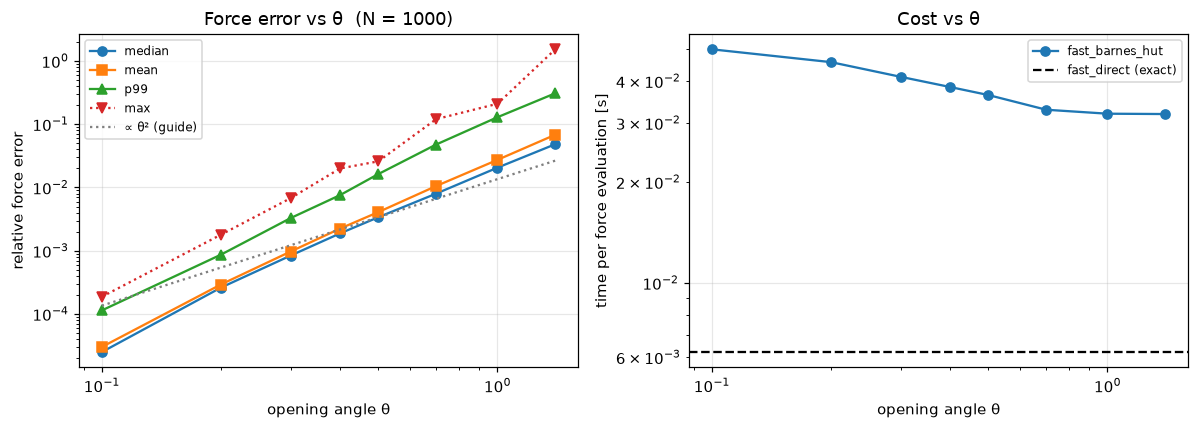

,theta,time_s,median,mean,p99,max,slope_median,slope_p99
0,0.1,0.049752,0.000025,0.000030,0.000114,0.000187,NaN,NaN
1,0.2,0.045559,0.000261,0.000293,0.000866,0.001794,3.385172,2.927752
2,0.3,0.041188,0.000838,0.000971,0.003280,0.006771,2.875943,3.283177
3,0.4,0.038402,0.001879,0.002239,0.007568,0.019976,2.807097,2.906075
4,0.5,0.036340,0.003389,0.004085,0.016307,0.025918,2.642428,3.440270
5,0.7,0.032849,0.008002,0.010546,0.047793,0.120332,2.553393,3.195842
6,1.0,0.031967,0.020580,0.027330,0.129071,0.210634,2.648525,2.785390
7,1.4,0.031891,0.048321,0.068287,0.308509,1.528660,2.536742,2.589782


In [9]:
x, v, m = compare.plummer_sphere(N_FORCE, SEED)
t_ref, a_ref = compare.time_call(compare.make_callable(REF, modules[REF], EPS, 0.5, G), x, m, repeats=3)

snap, rows = {}, []
for th in THETAS:
    t, a = tree_run(x, m, th)
    e = compare.relative_force_error(a, a_ref)
    snap[th] = (a, e)
    rows.append({"theta": th, "time_s": t["min"], **compare.error_stats(e)})
f1 = pd.DataFrame(rows)

# local log-log slope d ln(err) / d ln(theta) between neighbouring grid points
lt = np.log(f1.theta.values)
for col in ("median", "p99"):
    f1[f"slope_{col}"] = np.r_[np.nan, np.diff(np.log(f1[col].values)) / np.diff(lt)]

small = f1.theta <= 0.7
for col in ("median", "p99"):
    p = np.polyfit(np.log(f1.theta[small]), np.log(f1[col][small]), 1)[0]
    print(f"power-law fit, theta <= 0.7:  {col:6s} error ~ theta^{p:.2f}")
print(f"direct ({REF}) time for the same snapshot: {t_ref['min']:.4f} s")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for col, mk in (("median", "o-"), ("mean", "s-"), ("p99", "^-"), ("max", "v:")):
    ax[0].plot(f1.theta, f1[col], mk, label=col)
th_ref = f1.theta.iloc[(f1.theta - 0.5).abs().argmin()]
y0 = f1.loc[f1.theta == th_ref, "median"].iloc[0]
tt = np.array([f1.theta.min(), f1.theta.max()])
ax[0].plot(tt, y0 * (tt / th_ref) ** 2, ":", color="gray", label="∝ θ² (guide)")
ax[0].set(xscale="log", yscale="log", xlabel="opening angle θ", ylabel="relative force error",
          title=f"Force error vs θ  (N = {N_FORCE})")
ax[0].legend(fontsize=8)

ax[1].plot(f1.theta, f1.time_s, "o-", label=TREE)
ax[1].axhline(t_ref["min"], color="k", ls="--", label=f"{REF} (exact)")
ax[1].set(xscale="log", yscale="log", xlabel="opening angle θ", ylabel="time per force evaluation [s]",
          title="Cost vs θ")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

f1.round(6)

## 2. Who pays the error?

Left: the empirical CDF of per-particle error. The gap between the median and the tail is the real cost of a large θ, because a few particles can be badly wrong while the typical one is fine. Right: median error binned by distance from the centre of mass (equal-count bins). Errors tend to be largest where the force is small (near the centre, where contributions nearly cancel) so a *relative* error is inflated there even though the absolute error is not.

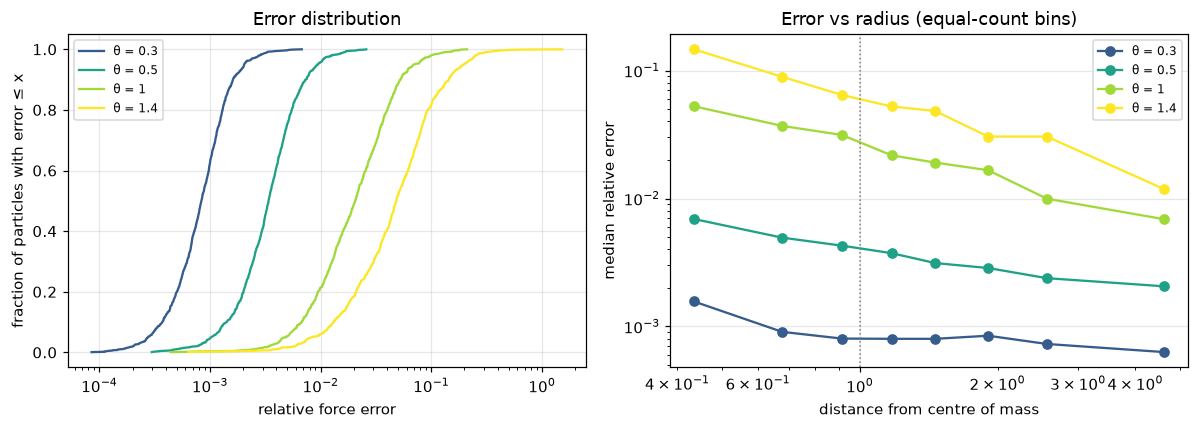

In [10]:
sel = sorted({min(THETAS, key=lambda t: abs(t - s)) for s in (0.3, 0.5, 1.0, 1.4)})
com = np.average(x, weights=m, axis=0)
r = np.linalg.norm(x - com, axis=1)
NB = 8
edges = np.quantile(r, np.linspace(0, 1, NB + 1))
bin_id = np.clip(np.digitize(r, edges[1:-1]), 0, NB - 1)
r_mid = np.array([np.median(r[bin_id == k]) for k in range(NB)])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for th in sel:
    e = snap[th][1]
    es = np.sort(e)
    ax[0].plot(es, np.arange(1, len(es) + 1) / len(es), color=theta_color[th], label=f"θ = {th:g}")
    ax[1].plot(r_mid, [np.median(e[bin_id == k]) for k in range(NB)], "o-", color=theta_color[th], label=f"θ = {th:g}")
ax[0].set(xscale="log", xlabel="relative force error", ylabel="fraction of particles with error ≤ x",
          title="Error distribution")
ax[0].legend(fontsize=8)
ax[1].set(xscale="log", yscale="log", xlabel="distance from centre of mass", ylabel="median relative error",
          title="Error vs radius (equal-count bins)")
ax[1].axvline(1.0, color="gray", ls=":", lw=1)   # Plummer scale radius a = 1
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Is the error biased, and what does it do to Newton's third law?

Split the error of each particle into a component **along** the true force, `a·a_ref/|a_ref|² − 1` (signed: negative means the tree force is too weak), and a component **perpendicular** to it. A systematic negative bias would mean the tree makes the cluster feel less bound than it is.

Pairwise-symmetric forces sum to zero, so `|Σ mᵢ aᵢ|` measures how badly the tree violates momentum conservation. Normalised by `Σ mᵢ|aᵢ|` it is a dimensionless rate that is directly comparable across θ, and the exact solver gives the roundoff floor.

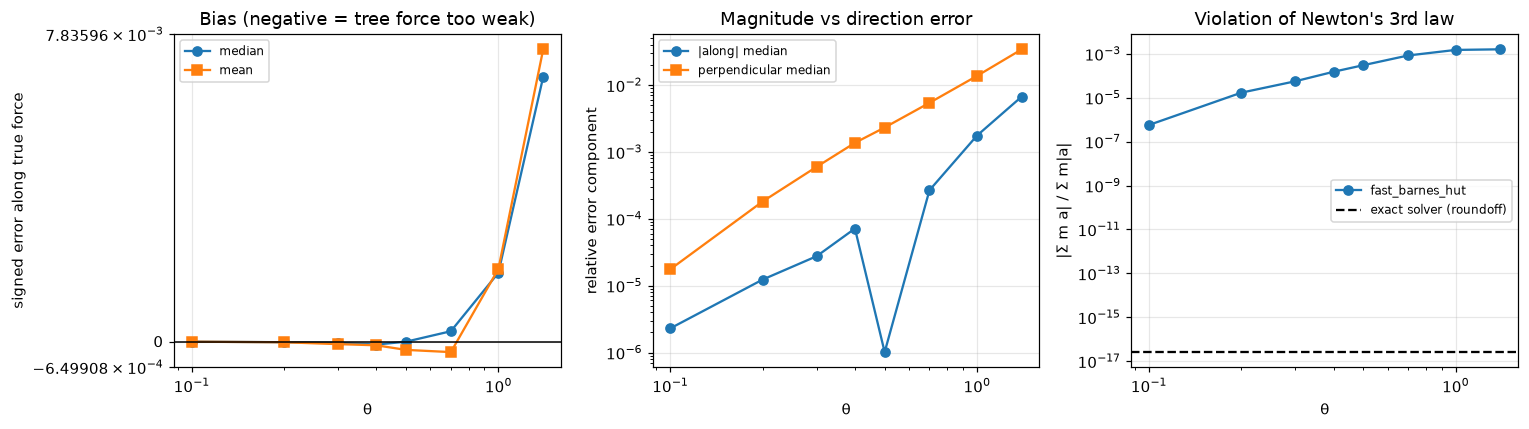

,theta,par_median,par_mean,frac_too_weak,perp_median,net_force_frac
0,0.1,0.000002,0.000001,0.451,0.000018,0.000001
1,0.2,-0.000012,-0.000013,0.530,0.000181,0.000017
2,0.3,-0.000028,-0.000061,0.520,0.000599,0.000056
3,0.4,-0.000072,-0.000091,0.520,0.001370,0.000151
4,0.5,0.000001,-0.000208,0.499,0.002321,0.000301
5,0.7,0.000268,-0.000264,0.484,0.005435,0.000835
6,1.0,0.001757,0.001853,0.445,0.013726,0.001494
7,1.4,0.006748,0.007450,0.381,0.034318,0.001595


In [11]:
def force_diagnostics(a, a_ref, m):
    par = np.sum(a * a_ref, axis=1) / np.sum(a_ref**2, axis=1) - 1.0
    perp = np.linalg.norm(a - (par + 1.0)[:, None] * a_ref, axis=1) / np.linalg.norm(a_ref, axis=1)
    net = np.linalg.norm(np.sum(m[:, None] * a, axis=0)) / np.sum(m * np.linalg.norm(a, axis=1))
    return par, perp, net

rows = []
for th in THETAS:
    par, perp, net = force_diagnostics(snap[th][0], a_ref, m)
    rows.append({"theta": th, "par_median": np.median(par), "par_mean": par.mean(),
                 "frac_too_weak": float(np.mean(par < 0)), "perp_median": np.median(perp), "net_force_frac": net})
bias = pd.DataFrame(rows)
net_floor = force_diagnostics(a_ref, a_ref, m)[2]

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(bias.theta, bias.par_median, "o-", label="median")
ax[0].plot(bias.theta, bias.par_mean, "s-", label="mean")
ax[0].axhline(0, color="k", lw=1)
ax[0].set(xscale="log", yscale="symlog", xlabel="θ", ylabel="signed error along true force",
          title="Bias (negative = tree force too weak)")
ax[0].legend(fontsize=8)

ax[1].plot(bias.theta, bias.par_median.abs(), "o-", label="|along| median")
ax[1].plot(bias.theta, bias.perp_median, "s-", label="perpendicular median")
ax[1].set(xscale="log", yscale="log", xlabel="θ", ylabel="relative error component",
          title="Magnitude vs direction error")
ax[1].legend(fontsize=8)

ax[2].plot(bias.theta, bias.net_force_frac, "o-", label=TREE)
ax[2].axhline(max(net_floor, 1e-17), color="k", ls="--", label="exact solver (roundoff)")
ax[2].set(xscale="log", yscale="log", xlabel="θ", ylabel="|Σ m a| / Σ m|a|",
          title="Violation of Newton's 3rd law")
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

bias.round(6)

## 4. Cost vs θ, and how it changes with N

For each N the exact solver is run once as a reference and the tree is run at every θ. From this one sweep we get time vs θ, speedup over direct summation, the error at each N (is it N-independent?), the effective N-scaling exponent for each θ, and where the tree starts beating direct summation.

In [12]:
rows = []
for n in N_SWEEP:
    xs, _, ms = compare.plummer_sphere(n, SEED)
    tr, a_r = compare.time_call(compare.make_callable(REF, modules[REF], EPS, 0.5, G), xs, ms, repeats=3)
    rows.append({"solver": REF, "n": n, "theta": np.nan, "time_min_s": tr["min"]})
    for th in THETAS:
        t, a = tree_run(xs, ms, th)
        rows.append({"solver": TREE, "n": n, "theta": th, "time_min_s": t["min"],
                     **compare.error_stats(compare.relative_force_error(a, a_r))})
    print(f"  N = {n:>6} done", flush=True)
sweep = pd.DataFrame(rows)
ref_df  = sweep[sweep.solver == REF].set_index("n")
tree_df = sweep[sweep.solver == TREE].copy()
tree_df["speedup"] = tree_df.apply(lambda r: ref_df.time_min_s[r.n] / r.time_min_s, axis=1)

  N =    500 done
  N =   1000 done
  N =   2000 done
  N =   4000 done


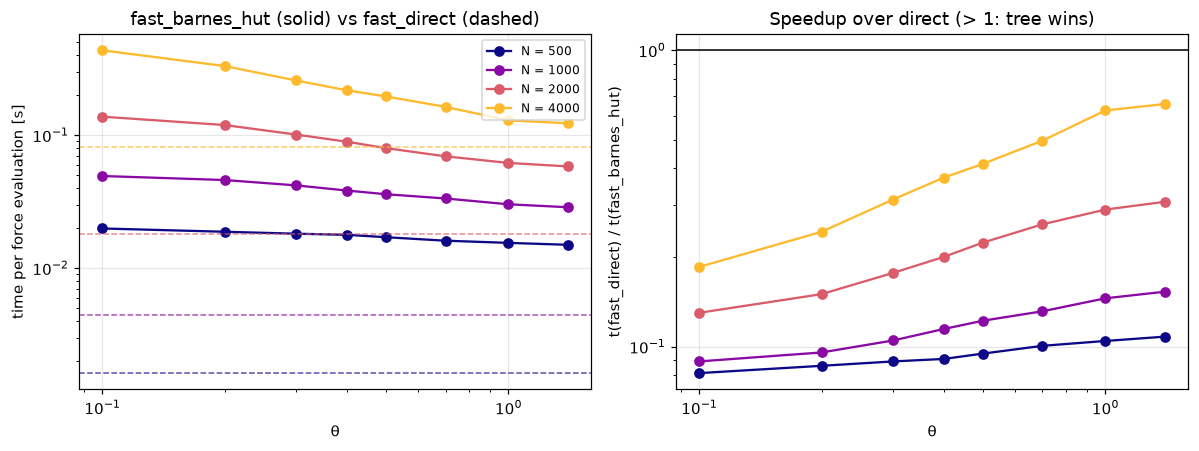

In [13]:
cmapN = {n: plt.cm.plasma(i / max(len(N_SWEEP) - 1, 1) * 0.85) for i, n in enumerate(N_SWEEP)}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for n, g in tree_df.groupby("n"):
    g = g.sort_values("theta")
    ax[0].plot(g.theta, g.time_min_s, "o-", color=cmapN[n], label=f"N = {n}")
    ax[0].axhline(ref_df.time_min_s[n], color=cmapN[n], ls="--", lw=1, alpha=.7)
    ax[1].plot(g.theta, g.speedup, "o-", color=cmapN[n], label=f"N = {n}")
ax[0].set(xscale="log", yscale="log", xlabel="θ", ylabel="time per force evaluation [s]",
          title=f"{TREE} (solid) vs {REF} (dashed)")
ax[1].axhline(1, color="k", lw=1)
ax[1].set(xscale="log", yscale="log", xlabel="θ", ylabel=f"t({REF}) / t({TREE})", title="Speedup over direct (> 1: tree wins)")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

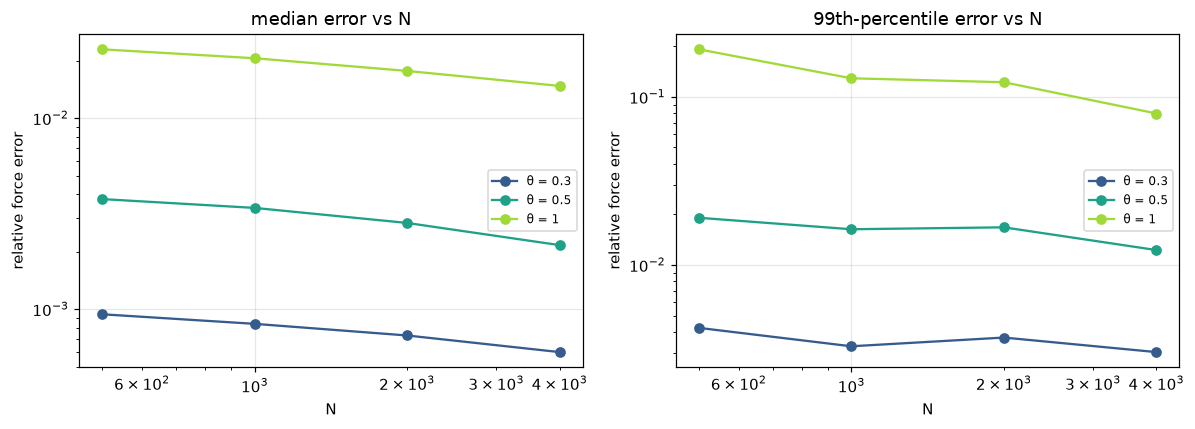

In [14]:
# Error vs N at fixed theta: does the accuracy of a given theta depend on system size?
sel_n = sorted({min(THETAS, key=lambda t: abs(t - s)) for s in (0.3, 0.5, 1.0)})
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for th in sel_n:
    g = tree_df[tree_df.theta == th].sort_values("n")
    ax[0].plot(g.n, g["median"], "o-", color=theta_color[th], label=f"θ = {th:g}")
    ax[1].plot(g.n, g["p99"], "o-", color=theta_color[th], label=f"θ = {th:g}")
for a_, title in zip(ax, ("median error", "99th-percentile error")):
    a_.set(xscale="log", yscale="log", xlabel="N", ylabel="relative force error", title=title + " vs N")
    a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

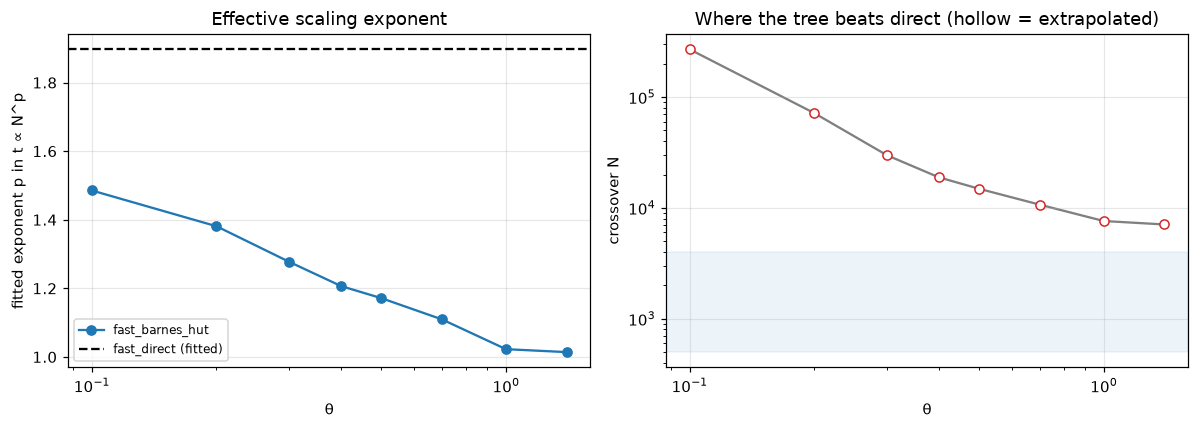

,theta,slope_tree,n_cross,extrapolated
0,0.1,1.485,269786.249,True
1,0.2,1.381,71690.954,True
2,0.3,1.277,29796.444,True
3,0.4,1.206,18868.839,True
4,0.5,1.171,14879.503,True
5,0.7,1.110,10707.840,True
6,1.0,1.023,7616.314,True
7,1.4,1.014,7090.895,True


In [15]:
# Effective scaling exponent per theta and the direct/tree crossover
rows = []
for th in THETAS:
    g = tree_df[tree_df.theta == th].sort_values("n")
    tail = g.tail(4)
    slope = np.polyfit(np.log(tail.n), np.log(tail.time_min_s), 1)[0] if len(tail) >= 3 else np.nan
    sub = ([{"solver": REF, "n": n, "time_min_s": t} for n, t in ref_df.time_min_s.items()] +
           [{"solver": TREE, "n": r.n, "time_min_s": r.time_min_s} for r in g.itertuples()])
    est = compare.estimate_crossover(sub, slow=REF, fast=TREE)
    rows.append({"theta": th, "slope_tree": slope,
                 "n_cross": est["n_cross"] if est else np.nan,
                 "extrapolated": est["extrapolated"] if est else None})
scal = pd.DataFrame(rows)
ref_pts = ref_df.reset_index().tail(4)
slope_ref = np.polyfit(np.log(ref_pts.n), np.log(ref_pts.time_min_s), 1)[0]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(scal.theta, scal.slope_tree, "o-", label=TREE)
ax[0].axhline(slope_ref, color="k", ls="--", label=f"{REF} (fitted)")
ax[0].set(xscale="log", xlabel="θ", ylabel="fitted exponent p in t ∝ N^p", title="Effective scaling exponent")
ax[0].legend(fontsize=8)

ok = scal.dropna(subset=["n_cross"])
ax[1].plot(ok.theta, ok.n_cross, "-", color="gray", zorder=1)
for r_ in ok.itertuples():
    ax[1].plot(r_.theta, r_.n_cross, "o", color="tab:red", mfc="white" if r_.extrapolated else "tab:red", zorder=2)
ax[1].axhspan(min(N_SWEEP), max(N_SWEEP), color="tab:blue", alpha=.08)
ax[1].set(xscale="log", yscale="log", xlabel="θ", ylabel="crossover N",
          title="Where the tree beats direct (hollow = extrapolated)")
plt.tight_layout(); plt.show()

scal.round(3)

## 5. Realisation-to-realisation scatter

A single random Plummer sphere gives a single number per θ. Here the same θ grid is evaluated on several independent realisations (different seeds) to see how much of the structure in section 1 is noise. The 99th percentile depends on a handful of particles and is expected to be much noisier than the median.

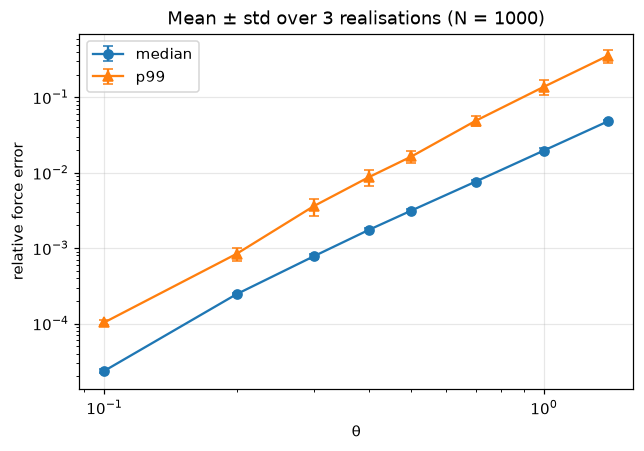

,rel. scatter (median),rel. scatter (p99)
theta,,
0.1,0.064,0.071
0.2,0.023,0.205
0.3,0.080,0.256
0.4,0.069,0.227
0.5,0.042,0.173
0.7,0.054,0.139
1.0,0.080,0.217
1.4,0.044,0.202


In [16]:
rows = []
for s in SEEDS:
    xs, _, ms = compare.plummer_sphere(N_FORCE, s)
    a_r = accel(REF, xs, ms)
    for th in THETAS:
        e = compare.relative_force_error(accel(TREE, xs, ms, th), a_r)
        rows.append({"seed": s, "theta": th, **compare.error_stats(e)})
seeds_df = pd.DataFrame(rows)
agg = seeds_df.groupby("theta")[["median", "p99"]].agg(["mean", "std"])

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for col, mk in (("median", "o"), ("p99", "^")):
    ax.errorbar(agg.index, agg[(col, "mean")], yerr=agg[(col, "std")], fmt=mk + "-", capsize=3, label=col)
ax.set(xscale="log", yscale="log", xlabel="θ", ylabel="relative force error",
       title=f"Mean ± std over {len(list(SEEDS))} realisations (N = {N_FORCE})")
ax.legend()
plt.show()

(agg[("median", "std")] / agg[("median", "mean")]).rename("rel. scatter (median)").to_frame().join(
    (agg[("p99", "std")] / agg[("p99", "mean")]).rename("rel. scatter (p99)")).round(3)

## 6. θ and the dynamics

Same Plummer sphere, same leapfrog and timestep for every run; only θ changes, with the exact solver as the baseline. The exact run shows the integrator's own energy error, so the question is at what θ the tree error rises clearly **above that floor**. Momentum drift is purely a tree effect (see section 3). Trajectories are not compared point by point because the system is chaotic; the virial ratio and half-mass radius are the statistical checks.

  leapfrog with fast_barnes_hut, theta = 0.3
  leapfrog with fast_barnes_hut, theta = 0.5
  leapfrog with fast_barnes_hut, theta = 1.0


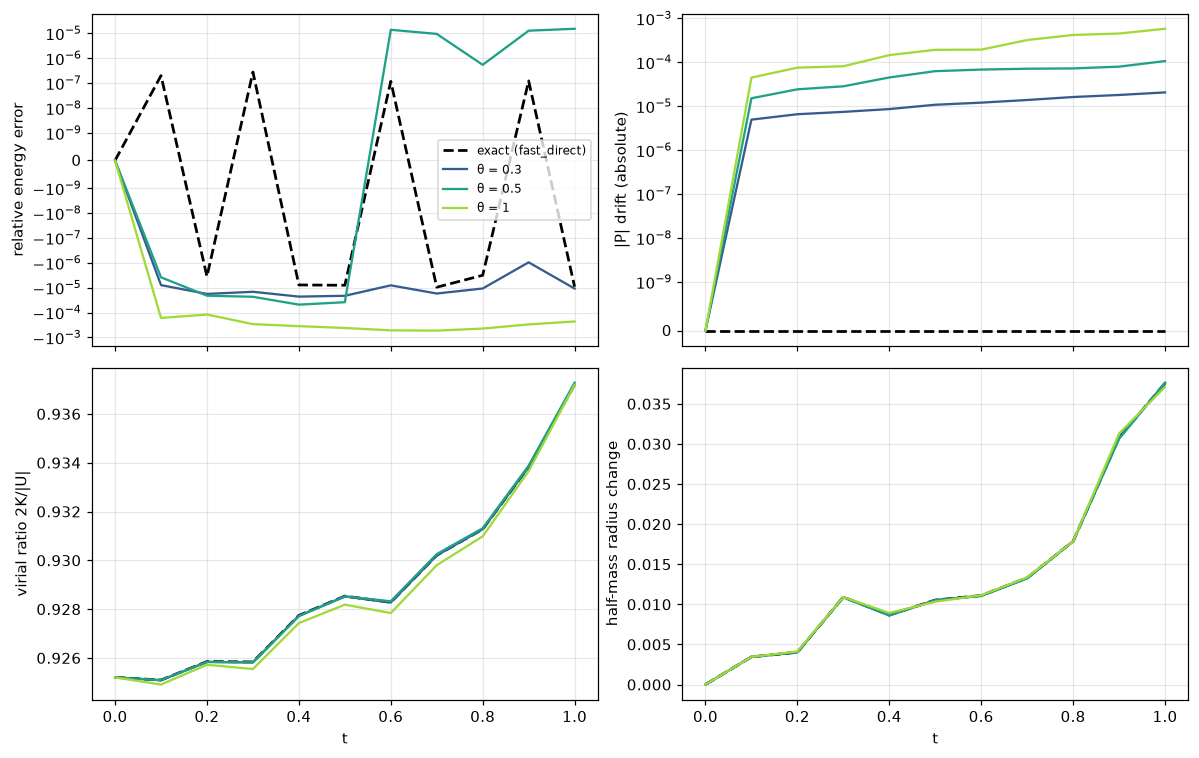

,max |dE/E|,final |P| drift,final dL/L,final d r_half,force wall time [s]
exact,0.000010,6.073271e-18,-8.035133e-16,0.037579,0.019080
θ=0.3,0.000023,2.062463e-05,7.656981e-06,0.037551,0.676510
θ=0.5,0.000048,1.067109e-04,7.232973e-05,0.037640,0.651930
θ=1,0.000536,5.800722e-04,3.171115e-03,0.037107,0.649296


In [17]:
x0, v0, m0 = compare.plummer_sphere(N_CONS, SEED)

def run(name, th):
    fn = compare.make_callable(name, modules[name], EPS, th, G)
    series, timing = compare.leapfrog_run(fn, x0, v0, m0, EPS, DT, STEPS, DIAG_EVERY, G)
    df = pd.DataFrame(series)
    df["wall_force_s"] = timing["wall_force"]
    return df

runs = {"exact": run(REF, 0.5)}
for th in THETAS_CONS:
    print(f"  leapfrog with {TREE}, theta = {th}", flush=True)
    runs[th] = run(TREE, th)

fig, ax = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
panels = [("dE_rel", "relative energy error", "symlog"), ("p_drift", "|P| drift (absolute)", "symlog"),
          ("virial", "virial ratio 2K/|U|", "linear"), ("dr_half_rel", "half-mass radius change", "linear")]
for a_, (col, label, scale) in zip(ax.ravel(), panels):
    for key, g in runs.items():
        if key == "exact":
            a_.plot(g.t, g[col], "k--", lw=1.8, label=f"exact ({REF})")
        else:
            a_.plot(g.t, g[col], color=theta_color.get(key, plt.cm.viridis(0.5)), lw=1.5, label=f"θ = {key:g}")
    a_.set(ylabel=label)
    if scale == "symlog":
        a_.set_yscale("symlog", linthresh=1e-9)
ax[1, 0].set_xlabel("t"); ax[1, 1].set_xlabel("t")
ax[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

dyn = pd.DataFrame({
    ("exact" if k == "exact" else f"θ={k:g}"): {
        "max |dE/E|": g.dE_rel.abs().max(), "final |P| drift": g.p_drift.iloc[-1],
        "final dL/L": g.dL_rel.iloc[-1], "final d r_half": g.dr_half_rel.iloc[-1],
        "force wall time [s]": g.wall_force_s.iloc[0]}
    for k, g in runs.items()}).T
dyn

## 7. Choosing θ for an error target

For each N and error target, the table gives the **cheapest θ on the grid** whose error is at or below the target, with the speedup over direct summation that buys. The grid is coarse, so treat the result as "θ of roughly this size", not an optimum. The scatter shows the same trade-off at fixed N: each point is one θ, and the vertical dashed line is the cost of exact summation.

cheapest theta on the grid with p99 force error <= tol  (NaN: no theta in the grid is accurate enough)


theta             speedup            
tol  0.001 0.003 0.010   0.001 0.003 0.010
n                                         
500    0.1   0.2   0.4    0.08  0.09  0.09
1000   0.2   0.2   0.4    0.10  0.10  0.11
2000   0.1   0.2   0.4    0.13  0.15  0.20
4000   0.2   0.2   0.4    0.24  0.24  0.37

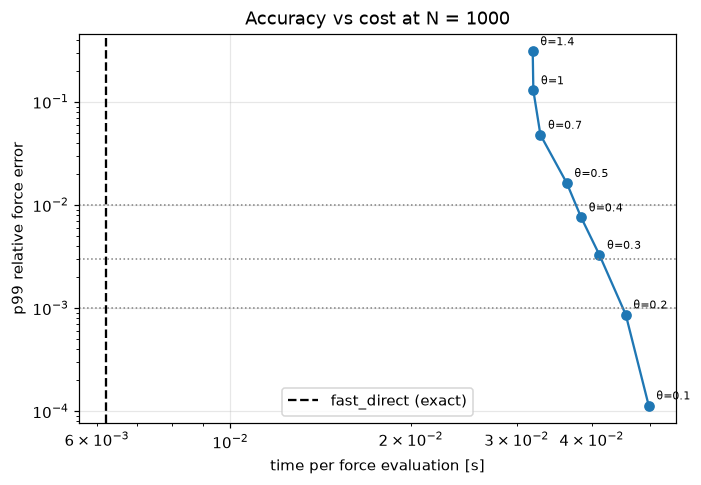

In [18]:
TOLS, METRIC = (1e-2, 3e-3, 1e-3), "p99"      # METRIC may be "median", "mean", "p99" or "max"
rows = []
for n, g in tree_df.groupby("n"):
    for tol in TOLS:
        ok = g[g[METRIC] <= tol]
        if ok.empty:
            rows.append({"n": n, "tol": tol, "theta": np.nan, "speedup": np.nan}); continue
        best = ok.sort_values("time_min_s").iloc[0]
        rows.append({"n": n, "tol": tol, "theta": best.theta, "speedup": best.speedup})
choose = pd.DataFrame(rows).pivot(index="n", columns="tol", values=["theta", "speedup"])
print(f"cheapest theta on the grid with {METRIC} force error <= tol  (NaN: no theta in the grid is accurate enough)")
display(choose.round(2))

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.plot(f1.time_s, f1[METRIC], "o-")
for r_ in f1.itertuples():
    ax.annotate(f"θ={r_.theta:g}", (r_.time_s, getattr(r_, METRIC)), textcoords="offset points", xytext=(5, 4), fontsize=7)
ax.axvline(t_ref["min"], color="k", ls="--", label=f"{REF} (exact)")
for tol in TOLS:
    ax.axhline(tol, color="gray", ls=":", lw=1)
ax.set(xscale="log", yscale="log", xlabel="time per force evaluation [s]",
       ylabel=f"{METRIC} relative force error", title=f"Accuracy vs cost at N = {N_FORCE}")
ax.legend()
plt.show()

In [19]:
# Save everything computed here so the plots can be regenerated without re-running the solvers
OUT.mkdir(parents=True, exist_ok=True)
f1.to_csv(OUT / "theta_force_error.csv", index=False)
bias.to_csv(OUT / "theta_bias.csv", index=False)
sweep.to_csv(OUT / "theta_vs_n.csv", index=False)
scal.to_csv(OUT / "theta_scaling.csv", index=False)
seeds_df.to_csv(OUT / "theta_seeds.csv", index=False)
dyn.to_csv(OUT / "theta_dynamics_summary.csv")
print("saved to", OUT.resolve())

saved to /Users/henry/Desktop/p332/PHYS332-FP/Henry/results_theta


## 8. Reading the results

* **Force-error exponent (section 1).** An exponent of roughly 2 to 3 is consistent with quadrupole-dominated error. A local slope that grows or flattens at large θ marks where the opening criterion stops being a good proxy for the true truncation error.
* **Median vs tail (sections 1 and 2).** A modest median can hide a large 99th percentile. If your science cares about the worst-behaved particles (halo stars, close encounters), size θ from the tail, not the median.
* **Bias (section 3).** A consistent negative along-force bias means the tree systematically under-binds. This is more damaging in long runs than random error of the same size. The net-force fraction is the per-evaluation momentum violation: the rate at which total momentum can walk.
* **Cost (section 4).** Cost should fall steeply as θ rises, but the speedup over direct summation is capped by tree-build time (see section 4 of the main notebook), so very large θ stops paying off.
* **Crossover (section 4).** Smaller θ pushes the crossover to larger N. A crossover well above your working N means direct summation is the better choice at that accuracy.
* **Dynamics (section 6).** Compare the tree's energy error with the exact solver's. If they match, the integrator dominates and a smaller θ is wasted effort. If the tree is clearly worse, use the table in section 7 to pick the θ whose force error stays under your tolerance.
* **Caveats.** Plummer sphere only (centrally concentrated, equal masses), monopole-order cells, fixed softening ε = 0.05, single-threaded Numba, one short integration. Clustered or cold-collapse initial conditions can have very different θ sensitivity, and the choice of θ should be re-checked on the system you actually care about.